# 02 · La popularité, source par source

On a trois sources de popularité qui couvrent (presque) tous les Pokémon :
- **Reddit 2019** : des votes, 809 Pokémon (générations 1 à 7) ;
- **Johto Times 2025** : la part des votes **dans la génération**, 1 025 Pokémon ;
- **Google Trends** : l'intérêt de recherche par pays, qu'il faut ramener sur l'échelle de Gengar.

Comme on l'a dit dans le notebook 01, on ne veut pas les fusionner en un seul score. Mais pour pouvoir les comparer, il faut quand même les mettre sur une échelle commune, parce qu'elles n'ont ni le même nombre de votants ni les mêmes unités. L'idée qu'on a retenue, c'est le **percentile** : dans chaque source, on dit « ce Pokémon fait mieux que X % des Pokémon de la source ». Un percentile de 0,9 veut dire la même chose partout, quelle que soit la taille du sondage.

À la fin, on obtient une matrice Pokémon × sources, et on regarde qui est populaire partout, seulement quelque part, ou nulle part.

*Pokémon of the Year 2020 n'est pas dedans pour l'instant : il n'a que des noms, et l'harmonisation des noms c'est la partie de Lucas.*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
RAW = Path("../data/raw")
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
table.shape

(1025, 31)

## 1. Google Trends : découverte

Rappel de la collecte : 256 lots de 5 termes, chaque lot contient Gengar (l'ancre) + 4 Pokémon. Dans chaque pays, les 5 termes d'un lot se partagent 100.

In [2]:
gt = pd.read_csv(RAW / "google_trends/interet_par_pays.csv")
print(gt.shape)
print("pays :", gt.pays.nunique(), "| termes :", gt.terme.nunique(), "| lots :", gt.lot.nunique())
gt.head()

(320000, 4)
pays : 250 | termes : 1025 | lots : 256


,pays,terme,valeur,lot
0,Afghanistan,Gengar,100,0
1,Albania,Gengar,46,0
2,Algeria,Gengar,35,0
3,American Samoa,Gengar,0,0
4,Andorra,Gengar,50,0


On a 320 000 lignes : 256 lots × 250 « pays » (Google compte aussi des territoires comme l'Antarctique ou l'île Bouvet) × 5 termes. Chaque lot a bien ses 5 termes, dont Gengar.

In [3]:
# est-ce que chaque lot a bien 5 termes, dont Gengar ?
par_lot = gt.groupby("lot")["terme"].agg(["nunique", lambda t: "Gengar" in set(t)])
par_lot.columns = ["nb_termes", "contient_gengar"]
print(par_lot["nb_termes"].value_counts())
print(par_lot["contient_gengar"].value_counts())

nb_termes
5    256
Name: count, dtype: int64
contient_gengar
True    256
Name: count, dtype: int64


In [4]:
# les lignes d'un même pays et d'un même lot font-elles bien 100 ?
somme = gt.groupby(["lot", "pays"])["valeur"].sum()
somme.describe()

count    64000.000000
mean        70.087500
std         45.787827
min          0.000000
25%          0.000000
50%        100.000000
75%        100.000000
max        100.000000
Name: valeur, dtype: float64

In [5]:
somme.value_counts().head(10)

valeur
100    44856
0      19144
Name: count, dtype: int64

La somme d'un lot dans un pays vaut **soit 100, soit 0**, jamais autre chose. Quand c'est 0, Google n'a simplement pas assez de recherches dans ce pays pour donner une valeur.

In [6]:
# relier chaque terme à un numéro de Pokédex (4 termes ont été écrits autrement que dans PokéAPI)
corrections = {"Farfetch'd": "Farfetch’d", "Sirfetch'd": "Sirfetch’d", "Mime Jr": "Mime Jr.", "Mr Rime": "Mr. Rime"}
nom_vers_dex = pd.Series(table.index, index=table["nom_en"])
gt["nom_en"] = gt["terme"].replace(corrections)
gt["dex"] = gt["nom_en"].map(nom_vers_dex)
print("termes sans numéro :", gt.loc[gt.dex.isna(), "terme"].unique())
print("Pokémon couverts :", gt.dex.nunique())

termes sans numéro : <StringArray>
[]
Length: 0, dtype: str
Pokémon couverts : 1025


Les 1 025 Pokémon ont tous leur numéro de Pokédex, la correction des 4 termes a marché.

In [7]:
# Gengar est dans tous les lots : on regarde sa valeur dans chaque pays
gengar = gt[gt.terme == "Gengar"]
print("lignes Gengar :", len(gengar))
print("part des (lot, pays) où Gengar vaut 0 :", round((gengar.valeur == 0).mean(), 3))
gengar.groupby("pays")["valeur"].agg(["mean", "min", "max", lambda v: (v == 0).mean()]).rename(columns={"<lambda_0>": "part_zero"}).sort_values("part_zero", ascending=False).head(15)

lignes Gengar : 64000
part des (lot, pays) où Gengar vaut 0 : 0.316


,mean,min,max,part_zero
pays,,,,
Anguilla,0.0,0,0,1.0
American Samoa,0.0,0,0,1.0
Antarctica,0.0,0,0,1.0
Benin,0.0,0,0,1.0
Cocos (Keeling) Islands,0.0,0,0,1.0
Burundi,0.0,0,0,1.0
Burkina Faso,0.0,0,0,1.0
British Virgin Islands,0.0,0,0,1.0
British Indian Ocean Territory,0.0,0,0,1.0


Gengar vaut 0 dans 32 % des couples (lot, pays) : ce sont les petits pays et les territoires où tout le lot est vide.

In [8]:
# les autres Pokémon : combien de zéros ?
autres = gt[gt.terme != "Gengar"]
print("part de zéros chez les autres Pokémon :", round((autres.valeur == 0).mean(), 3))
zeros_pays = autres.groupby("pays")["valeur"].apply(lambda v: (v == 0).mean()).sort_values()
zeros_pays.describe()

part de zéros chez les autres Pokémon : 0.647


count    250.000000
mean       0.646754
std        0.389101
min        0.011719
25%        0.209717
50%        0.897461
75%        0.976318
max        1.000000
Name: valeur, dtype: float64

En dehors de Gengar, 65 % des valeurs sont des 0. Dans les gros pays (Irlande, Royaume-Uni, Canada…) il n'y a presque pas de 0, alors que dans beaucoup de petits pays il n'y a quasiment que ça.

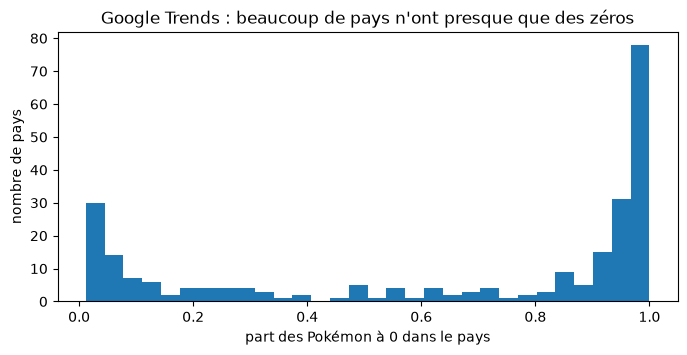

(pays
 Ireland           0.011719
 Thailand          0.013672
 United Kingdom    0.016602
 Portugal          0.017578
 Vietnam           0.017578
 Australia         0.019531
 Finland           0.019531
 Canada            0.019531
 Norway            0.021484
 Spain             0.021484
 Name: valeur, dtype: float64,
 pays
 Heard & McDonald Islands                  1.0
 French Southern Territories               1.0
 British Indian Ocean Territory            1.0
 Cocos (Keeling) Islands                   1.0
 Pitcairn Islands                          1.0
 Monaco                                    1.0
 Tokelau                                   1.0
 South Georgia & South Sandwich Islands    1.0
 U.S. Outlying Islands                     1.0
 Vatican City                              1.0
 Name: valeur, dtype: float64)

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(zeros_pays, bins=30)
ax.set_xlabel("part des Pokémon à 0 dans le pays")
ax.set_ylabel("nombre de pays")
ax.set_title("Google Trends : beaucoup de pays n'ont presque que des zéros")
plt.show()
zeros_pays.head(10), zeros_pays.tail(10)

## 2. Quels pays sont exploitables ?

Les valeurs d'un lot dans un pays font soit 100, soit 0. Quand ça fait 0, c'est que Google n'a pas assez de recherches dans ce pays pour donner une valeur : **le pays est vide pour ce lot**. Et si Gengar vaut 0 dans un lot, on ne peut pas diviser par lui.

Pour chaque pays, on regarde donc dans combien de lots Gengar a une valeur (non nulle).

In [10]:
couverture = gengar.groupby("pays")["valeur"].apply(lambda v: (v > 0).mean()).sort_values(ascending=False)
for seuil in [1.0, 0.99, 0.95, 0.9, 0.75, 0.5, 0.0001]:
    print(f"pays où Gengar a une valeur dans au moins {seuil:.0%} des lots : {(couverture >= seuil).sum()}")

pays où Gengar a une valeur dans au moins 100% des lots : 156
pays où Gengar a une valeur dans au moins 99% des lots : 170
pays où Gengar a une valeur dans au moins 95% des lots : 171
pays où Gengar a une valeur dans au moins 90% des lots : 171
pays où Gengar a une valeur dans au moins 75% des lots : 171
pays où Gengar a une valeur dans au moins 50% des lots : 171
pays où Gengar a une valeur dans au moins 0% des lots : 171


C'est tout ou rien : **171 pays** ont une valeur pour Gengar dans (presque) tous les lots, et les 79 autres n'en ont dans aucun. Les 171 pays sont donc tous utilisables pour la division par Gengar.

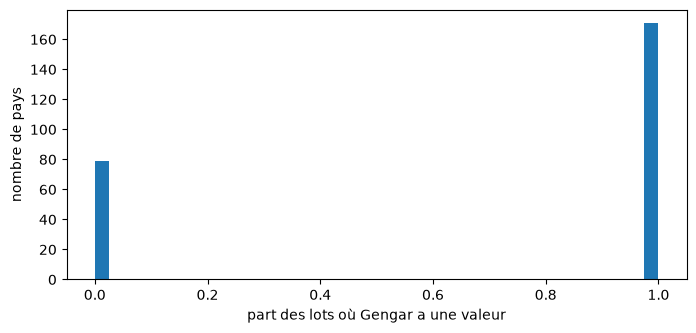

pays
Malaysia         0.996094
Haiti            0.996094
Albania          0.996094
Armenia          0.996094
Afghanistan      0.996094
Finland          0.996094
Cameroon         0.996094
Iran             0.996094
Côte d’Ivoire    0.996094
Uzbekistan       0.996094
Madagascar       0.996094
Senegal          0.996094
Tanzania         0.996094
Uganda           0.996094
Somalia          0.984375
Name: valeur, dtype: float64

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(couverture, bins=40)
ax.set_xlabel("part des lots où Gengar a une valeur")
ax.set_ylabel("nombre de pays")
plt.show()
couverture[(couverture < 1) & (couverture > 0)].head(30)

Les quelques pays à 99,6 % ont juste un lot vide sur 256.

In [12]:
# quand Gengar a une valeur, quelle est sa part dans le lot ? (ça dit la précision qu'on aura)
g_pos = gengar[gengar.valeur > 0]
g_pos.groupby("pays")["valeur"].median().describe()

count    171.000000
mean      90.824561
std        7.582192
min       74.000000
25%       84.000000
50%       89.000000
75%      100.000000
max      100.000000
Name: valeur, dtype: float64

Gengar prend en médiane **89 %** du lot à lui tout seul. Les 4 autres Pokémon se partagent les 11 % qui restent, avec des valeurs entières. Gengar était un choix d'ancre trop populaire : la précision pour les autres Pokémon est faible (on ne distingue pas un Pokémon à 0,3 % de Gengar d'un Pokémon à 0 %).

## 3. Ramener tout le monde sur l'échelle de Gengar

Dans chaque pays et chaque lot, on divise la valeur du Pokémon par celle de Gengar. Un ratio de 0,5 veut dire « ce Pokémon est deux fois moins cherché que Gengar dans ce pays ». On ne garde que les (lot, pays) où Gengar a une valeur.

In [13]:
g_val = gengar.set_index(["lot", "pays"])["valeur"].rename("gengar")
ratio = autres.join(g_val, on=["lot", "pays"])
ratio = ratio[ratio.gengar > 0].copy()
ratio["ratio"] = ratio["valeur"] / ratio["gengar"]
print(ratio.shape, "| pays :", ratio.pays.nunique())
ratio["ratio"].describe()

(175032, 8) | pays : 171


count    175032.000000
mean          0.127912
std           1.296022
min           0.000000
25%           0.000000
50%           0.010526
75%           0.056180
max          99.000000
Name: ratio, dtype: float64

In [14]:
# Gengar est dans les 256 lots : on lui donne un ratio de 1 dans chaque pays où il est présent
gengar_ratio = pd.DataFrame({"pays": ratio.pays.unique(), "dex": nom_vers_dex["Gengar"], "ratio": 1.0})
ratio_long = pd.concat([ratio[["pays", "dex", "ratio"]], gengar_ratio])
mat_ratio = ratio_long.pivot_table(index="dex", columns="pays", values="ratio")
mat_ratio.shape

(1025, 171)

Une fois ramené sur l'échelle de Gengar, on a une matrice de 1 025 Pokémon × 171 pays.

In [15]:
# les Pokémon les plus cherchés, en médiane sur les pays
mat_ratio.median(axis=1).sort_values(ascending=False).head(15).rename(table["nom_fr"])

dex
Pikachu       6.076923
Persian       4.875000
Arceus        3.347826
Mew           3.100000
Dracaufeu     2.560000
Fermite       2.492611
Galekid       1.969697
Grolem        1.892519
Évoli         1.875000
Métamorph     1.720779
Électrode     1.529412
Mewtwo        1.200000
Onix          1.137218
Abra          1.136364
Ectoplasma    1.000000
dtype: float64

Pikachu est en tête avec environ 6 fois les recherches de Gengar, ce qui est logique. Mais juste après, ça devient bizarre.

Problème de précision : comme Gengar prend souvent ~90 % du lot, les autres Pokémon n'ont que des petits entiers (0, 1, 2…). Un Pokémon peu cherché tombe à 0 et tous les 0 sont ex aequo. On regarde, pays par pays, la part de Pokémon à 0.

In [16]:
part_zero = (mat_ratio == 0).mean().sort_values()
nb_valeurs = mat_ratio.nunique().reindex(part_zero.index)
apercu = pd.DataFrame({"part_zero": part_zero, "nb_valeurs_differentes": nb_valeurs})
for s in [0.05, 0.1, 0.25, 0.5]:
    print(f"pays avec moins de {s:.0%} de Pokémon à 0 : {(part_zero < s).sum()}")
apercu.iloc[::10]

pays avec moins de 5% de Pokémon à 0 : 31
pays avec moins de 10% de Pokémon à 0 : 48
pays avec moins de 25% de Pokémon à 0 : 67
pays avec moins de 50% de Pokémon à 0 : 85


,part_zero,nb_valeurs_differentes
pays,,
Ireland,0.011707,379
Philippines,0.022439,327
Denmark,0.035122,305
Uruguay,0.048780,287
Brazil,0.072195,285
Poland,0.107317,245
Czechia,0.195122,226
Morocco,0.274146,348
Cuba,0.400976,307


Seulement 31 pays ont moins de 5 % de Pokémon à 0, et 67 en ont moins de 25 %. Plus un pays a de 0, moins il y a de valeurs différentes : Sénégal ou Saint-Marin ne départagent presque aucun Pokémon.

Le haut du classement Google Trends est bizarre : Persian, Fermite (*Durant* en anglais, comme le joueur de NBA), Galekid (*Aron*, un prénom), Grolem (*Golem*), Métamorph (*Ditto*), Abra, Onix… Ce sont des **noms anglais qui sont aussi des mots courants** : on mesure les recherches sur le mot, pas sur le Pokémon. C'est la limite qu'on avait notée dans `sources_donnees.md`.

On regarde aussi où sont les grands pays qui cherchent dans une autre écriture (Japon, Corée, Chine).

In [17]:
for p in ["Japan", "South Korea", "China", "Taiwan", "United States", "France", "Germany", "Mexico", "Brazil"]:
    if p in part_zero.index:
        print(f"{p:15s} part de 0 : {part_zero[p]:.2f}")
    else:
        print(f"{p:15s} absent (pas assez de recherches)")

Japan           part de 0 : 0.05
South Korea     part de 0 : 0.03
China           part de 0 : 0.50
Taiwan          part de 0 : 0.04
United States   part de 0 : 0.02
France          part de 0 : 0.04
Germany         part de 0 : 0.28
Mexico          part de 0 : 0.13
Brazil          part de 0 : 0.07


Le Japon (5 % de 0), la Corée du Sud (3 %) et Taïwan (4 %) ont étonnamment peu de 0 alors qu'on cherche les noms anglais. La Chine est à 50 %, et l'Allemagne à 28 %.

### Les noms ambigus

On a vu que le haut du classement est gonflé par des noms qui sont aussi des mots : quand quelqu'un cherche « Persian » ou « Durant », il cherche souvent un chat persan ou un joueur de basket, pas le Pokémon. Notre question, c'est la popularité **des Pokémon**, donc ces recherches-là ne nous intéressent pas : elles mesurent un mot, pas un Pokémon.

Pour les repérer, on a d'abord fait une liste à la main, en regardant les Pokémon qui sortaient bizarrement haut (dans le monde ou dans un pays en particulier). Ça marche pour les cas les plus visibles, mais on risque d'en oublier. Du coup on complète avec une recherche plus systématique : on regarde quels noms anglais sont **aussi des mots du dictionnaire anglais**.

In [18]:
# 1) la liste faite à la main, en regardant les Pokémon qui sortaient bizarrement haut
A_LA_MAIN = ["Persian", "Durant", "Klink", "Klang", "Ditto", "Golem", "Abra", "Aron", "Electrode", "Paras", "Mew",
             "Onix",     # aussi une voiture (Chevrolet Onix), très vendue en Amérique du Sud
             "Munna",    # aussi un prénom / surnom courant en Asie du Sud
             "Yanma",    # aussi un mot turc (« combustion »)
             "Sandile",  # aussi un prénom courant en Afrique du Sud
             "Patrat",   # proche du roumain « pătrat » (carré)
             "Minun",    # « minun » = « mon » en finnois
             "Hypno",    # abréviation courante de « hypnose »
             "Volbeat",  # aussi un groupe de rock danois très connu
             "Kabuto"]   # « casque » en japonais, et une marque de casques

# 2) les noms anglais qui sont aussi des mots du dictionnaire anglais
# (on ne garde que les entrées en minuscules du dictionnaire, pour ne pas prendre les noms propres)
# pour les noms composés (Iron Hands, Roaring Moon…), on regarde si chaque mot est dans le dictionnaire
mots = {l.strip() for l in open("/usr/share/dict/words", encoding="utf-8", errors="ignore") if l.strip().islower()}
def est_des_mots(nom):
    morceaux = nom.lower().replace("-", " ").split()
    return len(morceaux) > 0 and all(m in mots for m in morceaux)
dans_dico = table[table.nom_en.map(est_des_mots)]

# pour chacun : son rang Google (médiane sur les pays) et son rang dans les sondages (Johto Times, dans la génération)
rang_google = mat_ratio.median(axis=1).rank(pct=True)
johto_tmp = pd.read_csv(RAW / "johto_times_2025/johto_times_2025_preliminaire.csv").set_index("dex")
rang_johto = johto_tmp.groupby("generation")["pct_generation"].rank(pct=True)
candidats = pd.DataFrame({
    "nom_fr": dans_dico.nom_fr,
    "nom_en": dans_dico.nom_en,
    "deja_a_la_main": dans_dico.nom_en.isin(A_LA_MAIN),
    "percentile_google": rang_google.reindex(dans_dico.index).round(2),
    "percentile_johto": rang_johto.reindex(dans_dico.index).round(2),
})
candidats["ecart"] = (candidats.percentile_google - candidats.percentile_johto).round(2)
print(len(candidats), "noms anglais sont aussi des mots (ou des mots composés) du dictionnaire")

# pour comparer : l'écart Google − Johto chez tous les Pokémon
ecart_tous = (rang_google - rang_johto).dropna()
print("écart Google − Johto chez tous les Pokémon : médiane", round(ecart_tous.median(), 2),
      "| 90e percentile", round(ecart_tous.quantile(0.9), 2))
candidats.sort_values("ecart", ascending=False)

52 noms anglais sont aussi des mots (ou des mots composés) du dictionnaire
écart Google − Johto chez tous les Pokémon : médiane -0.0 | 90e percentile 0.35


,nom_fr,nom_en,deja_a_la_main,percentile_google,percentile_johto,ecart
dex,,,,,,
101,Électrode,Electrode,True,0.99,0.19,0.80
46,Paras,Paras,True,0.99,0.23,0.76
44,Ortide,Gloom,False,0.98,0.23,0.75
632,Fermite,Durant,True,1.00,0.25,0.75
124,Lippoutou,Jynx,False,0.97,0.26,0.71
86,Otaria,Seel,False,0.97,0.34,0.63
177,Natu,Natu,False,0.95,0.38,0.57
76,Grolem,Golem,True,0.99,0.44,0.55
1010,Vert-de-Fer,Iron Leaves,False,0.71,0.16,0.55


Le dictionnaire trouve 52 noms, mais tous ne posent pas problème : Rowlet, Snivy ou Litten y sont (le dictionnaire de Linux est très large), et leur classement Google colle à celui des sondages. Un nom qui est un mot ne pose problème que si **les recherches sur le mot gonflent sa valeur Google**. Pour le voir, on compare son percentile Google à son percentile au Johto Times : chez l'ensemble des Pokémon, l'écart est de 0 en médiane, et seuls 10 % des Pokémon ont un écart de plus de **0,35**.

Du coup on décide de la règle suivante : un nom est « ambigu » s'il est dans notre liste faite à la main, **ou** s'il est un mot du dictionnaire **et** que son écart Google − Johto dépasse 0,35 (il est plus « cherché qu'aimé » que 90 % des Pokémon). Ça ajoute 8 noms à la liste : Gloom (Ortide), Jynx (Lippoutou), Seel (Otaria), Natu, Gastly (Fantominus, proche de *ghastly*) et trois Pokémon Paradoxe dont le nom est fait de mots courants : Iron Leaves (Vert-de-Fer), Iron Hands (Paume-de-Fer) et Iron Crown (Chef-de-Fer).

Au début, on voulait garder ces Pokémon en les signalant. Mais en avançant dans les notebooks (carte par pays, groupes de pays), on s'est rendu compte qu'ils **faussent les résultats** : Persian sortait « le plus cherché » dans 15 pays, Onix faisait ressortir l'Amérique du Sud à cause de la voiture… À chaque fois on mesurait un mot, pas un Pokémon. Or notre question porte sur les Pokémon. **On décide donc de les retirer de Google Trends** : pour ces Pokémon, la valeur Google devient manquante. Ils restent dans les sondages (Reddit, Johto Times), où le problème n'existe pas puisque les gens votent pour un Pokémon.

In [19]:
SEUIL_ECART = 0.35
par_le_dico = candidats[(candidats.ecart > SEUIL_ECART) & ~candidats.deja_a_la_main].nom_en.tolist()
AMBIGUS = A_LA_MAIN + par_le_dico
dex_ambigus = table.index[table.nom_en.isin(AMBIGUS)]
print("ajoutés par le dictionnaire :", par_le_dico)
print(len(dex_ambigus), "Pokémon retirés de Google Trends")

# on regarde une dernière fois leurs valeurs avant de les retirer
display(mat_ratio.loc[dex_ambigus].median(axis=1).sort_values(ascending=False)
        .rename(table["nom_fr"]).round(2).to_frame("ratio médian / Gengar"))

# on les retire de la matrice Google Trends (ils n'ont plus de valeur Google)
mat_ratio = mat_ratio.drop(index=dex_ambigus)
# et on recalcule la part de Pokémon à 0 dans chaque pays sans eux (elle sert à choisir les pays juste après)
part_zero = (mat_ratio == 0).mean().sort_values()
print("matrice Google Trends :", mat_ratio.shape)
mat_ratio.median(axis=1).sort_values(ascending=False).head(10).rename(table["nom_fr"]).round(2)

ajoutés par le dictionnaire : ['Gloom', 'Seel', 'Gastly', 'Jynx', 'Natu', 'Iron Hands', 'Iron Leaves', 'Iron Crown']
28 Pokémon retirés de Google Trends


,ratio médian / Gengar
dex,
Persian,4.88
Mew,3.10
Fermite,2.49
Galekid,1.97
Grolem,1.89
Métamorph,1.72
Électrode,1.53
Onix,1.14
Abra,1.14


matrice Google Trends : (997, 171)


dex
Pikachu       6.08
Arceus        3.35
Dracaufeu     2.56
Évoli         1.88
Mewtwo        1.20
Ectoplasma    1.00
Ronflex       0.72
Lucario       0.69
Salamèche     0.62
Rayquaza      0.61
dtype: float64

Une fois ces noms retirés, le haut du classement Google ressemble enfin à des Pokémon : Pikachu (6 fois Gengar), Arceus, Dracaufeu, Évoli, Mewtwo, Ectoplasma, Ronflex, Lucario…

En refaisant le classement sans eux, on a encore vu passer trois noms qui sont des mots, mais que le dictionnaire n'avait pas repérés : **Hypno** (Hypnomade), 8e dans le monde juste devant Lucario, alors que « hypno » est l'abréviation courante d'hypnose ; **Volbeat** (Muciole), qui est aussi un groupe de rock danois connu, et **Kabuto**, qui veut dire « casque » en japonais et est aussi une marque. On les a ajoutés à la liste faite à la main (c'est pour ça qu'ils sont dans la cellule au-dessus). Au total, **28 Pokémon** sont retirés de Google Trends.

On a aussi recalculé la part de Pokémon à 0 dans chaque pays sans eux, puisqu'elle sert juste après à choisir les pays.

## 4. Percentiles par pays

Dans chaque pays, on classe les Pokémon par ratio et on transforme le rang en percentile (de 0 à 1, 1 = le plus cherché). Les ex aequo (notamment tous les 0) reçoivent le même percentile, la moyenne de leurs rangs.

Le problème, c'est les pays avec plein de zéros : si 90 % des Pokémon sont à 0, ils sont tous ex aequo et le percentile ne veut plus rien dire. On a vu plus haut qu'on passe de 31 pays sous 5 % de zéros à 67 pays sous 25 %, puis 85 sous 50 %. **On décide de garder les pays qui ont moins de 25 % de Pokémon à 0** : en dessous, on perdrait des pays importants (Mexique, Pologne, Tchéquie…), et au-dessus, un pays sur deux ne départage presque plus que le haut du classement.

In [20]:
SEUIL_ZERO_PAYS = 0.25

pays_gardes = part_zero[part_zero < SEUIL_ZERO_PAYS].index
pct_pays = mat_ratio[pays_gardes].rank(pct=True)
print("pays gardés :", len(pays_gardes))
print(sorted(pays_gardes))

pays gardés : 67
['Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Bolivia', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Costa Rica', 'Croatia', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Finland', 'France', 'Greece', 'Guatemala', 'Honduras', 'Hong Kong', 'Hungary', 'India', 'Indonesia', 'Ireland', 'Israel', 'Italy', 'Japan', 'Malaysia', 'Mexico', 'Nepal', 'Netherlands', 'New Zealand', 'Norway', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Puerto Rico', 'Romania', 'Russia', 'Saudi Arabia', 'Serbia', 'Singapore', 'Slovakia', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'Thailand', 'Trinidad & Tobago', 'Türkiye', 'Ukraine', 'United Arab Emirates', 'United Kingdom', 'United States', 'Uruguay', 'Venezuela', 'Vietnam']


Avec ce seuil on garde **67 pays**. L'Allemagne (29 % de zéros) n'y est pas, de peu. On aurait pu monter le seuil pour la récupérer, mais ce serait choisir le seuil pour un pays en particulier, donc on le laisse à 25 %.

In [21]:
# quelle concordance entre les pays ? corrélation de Spearman entre les percentiles de chaque paire de pays
corr_pays = pct_pays.corr(method="spearman")
vals = corr_pays.values[np.triu_indices_from(corr_pays, 1)]
pd.Series(vals).describe()

count    2211.000000
mean        0.879986
std         0.040570
min         0.717030
25%         0.856320
50%         0.882461
75%         0.910239
max         0.976784
dtype: float64

Les pays se ressemblent énormément : la corrélation de Spearman médiane entre deux pays est de **0,88**, et la plus basse est encore de 0,72. En gros, les recherches Google suivent à peu près le même classement partout ; les différences entre pays existent mais elles sont petites par rapport à ce fond commun.

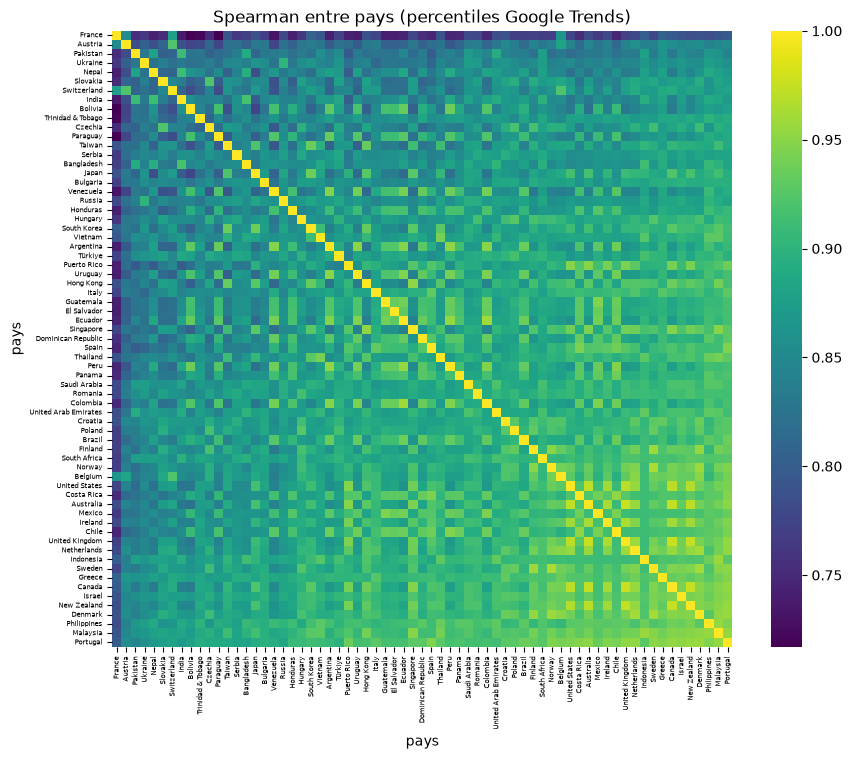

pays
France         0.774570
Austria        0.828057
Pakistan       0.838223
Ukraine        0.846713
Nepal          0.851408
Slovakia       0.851869
Switzerland    0.853704
India          0.856569
dtype: float64

In [22]:
ordre = corr_pays.mean().sort_values().index
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_pays.loc[ordre, ordre], cmap="viridis", ax=ax, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=5)
ax.set_title("Spearman entre pays (percentiles Google Trends)")
plt.show()
corr_pays.mean().sort_values().head(8)

La France est le pays qui ressemble le moins aux autres (0,78 en moyenne), suivie de l'Autriche et du Pakistan.

## 5. Les sondages : percentiles et incertitude

### Reddit 2019

On calcule deux percentiles : **global** (parmi les 809 Pokémon) et **dans la génération** (pour pouvoir comparer avec le Johto Times, qui ne se compare que dans une génération).

Pour l'incertitude : la part de votes d'un Pokémon est une proportion estimée sur ~52 700 votes. On calcule un **intervalle de confiance à 95 % (méthode de Wilson)** sur cette part, puis on regarde quels percentiles correspondent aux deux bornes. Si l'intervalle de percentile est très large, le classement du Pokémon n'est pas fiable.

In [23]:
from statsmodels.stats.proportion import proportion_confint

def percentile_de(valeurs_ref, x):
    # percentile d'une valeur x parmi les valeurs de référence (même convention que rank(pct=True), ex aequo au milieu)
    v = np.sort(valeurs_ref)
    return (np.searchsorted(v, x, "left") + np.searchsorted(v, x, "right")) / 2 / len(v)

r = table.loc[table.reddit_votes.notna(), ["generation", "reddit_votes"]].copy()
n_reddit = r.reddit_votes.sum()
bas, haut = proportion_confint(r.reddit_votes, n_reddit, alpha=0.05, method="wilson")
r["reddit_pct"] = r.reddit_votes.rank(pct=True)
r["reddit_pct_bas"] = percentile_de(r.reddit_votes, bas * n_reddit)
r["reddit_pct_haut"] = percentile_de(r.reddit_votes, haut * n_reddit)
r["reddit_pct_gen"] = r.groupby("generation")["reddit_votes"].rank(pct=True)
r["reddit_largeur_ic"] = r.reddit_pct_haut - r.reddit_pct_bas
r.sort_values("reddit_votes", ascending=False).head(8).assign(nom=lambda d: d.index.map(table.nom_fr))

,generation,reddit_votes,reddit_pct,reddit_pct_bas,reddit_pct_haut,reddit_pct_gen,reddit_largeur_ic,nom
dex,,,,,,,,
6,1,1107.0,1.000000,0.997528,1.000000,1.000000,0.002472,Dracaufeu
94,1,1056.0,0.998764,0.997528,1.000000,0.993377,0.002472,Ectoplasma
59,1,923.0,0.997528,0.996292,0.997528,0.986755,0.001236,Arcanin
1,1,710.0,0.996292,0.995056,0.996292,0.980132,0.001236,Bulbizarre
257,3,613.0,0.995056,0.988875,0.995056,1.000000,0.006180,Braségali
197,2,607.0,0.993820,0.988875,0.995056,1.000000,0.006180,Noctali
448,4,604.0,0.992583,0.988875,0.995056,1.000000,0.006180,Lucario
282,3,585.0,0.991347,0.986403,0.995056,0.992593,0.008653,Gardevoir


On retrouve le top connu du sondage Reddit : Dracaufeu, Ectoplasma, Arcanin, Bulbizarre… L'intervalle de confiance du haut du classement est minuscule (moins de 1 point de percentile).

In [24]:
# la largeur de l'intervalle (en points de percentile) selon le niveau de popularité
r["tranche"] = pd.cut(r.reddit_pct, [0, .25, .5, .75, .9, 1], labels=["0-25 %", "25-50 %", "50-75 %", "75-90 %", "90-100 %"])
r.groupby("tranche", observed=True)["reddit_largeur_ic"].describe()[["mean", "50%", "max"]]

,mean,50%,max
tranche,,,
0-25 %,0.255288,0.264524,0.307787
25-50 %,0.254281,0.250927,0.295426
50-75 %,0.172194,0.181706,0.243511
75-90 %,0.069705,0.072930,0.100124
90-100 %,0.016374,0.017305,0.025958


C'est le résultat important sur l'incertitude : dans la moitié basse de Reddit, l'intervalle de confiance fait **environ 25 points de percentile**. Un Pokémon classé au 30e percentile peut en réalité être n'importe où entre 15 et 40. En haut (top 10 %), l'intervalle ne fait plus que 2 points. Donc Reddit est fiable pour dire qui est très populaire, beaucoup moins pour classer les Pokémon peu aimés.

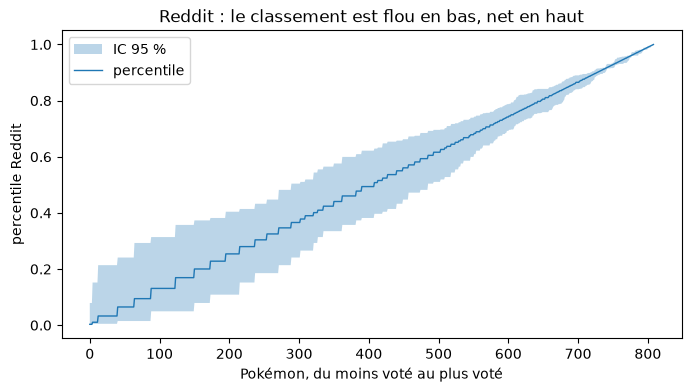

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
o = r.sort_values("reddit_pct")
ax.fill_between(range(len(o)), o.reddit_pct_bas, o.reddit_pct_haut, alpha=.3, label="IC 95 %")
ax.plot(range(len(o)), o.reddit_pct, lw=1, label="percentile")
ax.set_xlabel("Pokémon, du moins voté au plus voté")
ax.set_ylabel("percentile Reddit")
ax.legend()
ax.set_title("Reddit : le classement est flou en bas, net en haut")
plt.show()

### Johto Times 2025

Ici la part est déjà calculée **dans la génération** (`pct_generation` = votes / total des votes de la génération). On fait pareil : percentile dans la génération et intervalle de Wilson avec le total des votes de la génération.

In [26]:
johto = pd.read_csv(RAW / "johto_times_2025/johto_times_2025_preliminaire.csv").set_index("dex")
j = johto[["generation", "votes", "votes_total_generation", "participants_generation"]].copy()
bas, haut = proportion_confint(j.votes, j.votes_total_generation, alpha=0.05, method="wilson")
j["johto_pct_gen"] = j.groupby("generation")["votes"].rank(pct=True)
j["johto_pct_gen_bas"] = np.nan
j["johto_pct_gen_haut"] = np.nan
for g, d in j.groupby("generation"):
    j.loc[d.index, "johto_pct_gen_bas"] = percentile_de(d.votes, bas[d.index] * d.votes_total_generation)
    j.loc[d.index, "johto_pct_gen_haut"] = percentile_de(d.votes, haut[d.index] * d.votes_total_generation)
j["johto_largeur_ic"] = j.johto_pct_gen_haut - j.johto_pct_gen_bas
j["tranche"] = pd.cut(j.johto_pct_gen, [0, .25, .5, .75, .9, 1], labels=["0-25 %", "25-50 %", "50-75 %", "75-90 %", "90-100 %"])
j.groupby("tranche", observed=True)["johto_largeur_ic"].describe()[["mean", "50%", "max"]]

,mean,50%,max
tranche,,,
0-25 %,0.081675,0.083333,0.147436
25-50 %,0.096248,0.096154,0.160256
50-75 %,0.067928,0.067424,0.140741
75-90 %,0.037417,0.034091,0.091667
90-100 %,0.018281,0.018692,0.041667


Au Johto Times, avec environ 10 fois plus de votes, les intervalles sont bien plus étroits : 8 à 10 points en bas du classement et 2 points en haut.

In [27]:
# combien de votants par génération, et le nombre de votes du Pokémon médian
johto.groupby("generation").agg(participants=("participants_generation", "first"), votes_median=("votes", "median"), nb_pokemon=("votes", "size"))

,participants,votes_median,nb_pokemon
generation,,,
1,14478,268.0,151
2,12457,390.0,100
3,11452,225.0,135
4,10690,277.0,107
5,10107,184.0,156
6,9719,498.5,72
7,9642,420.5,88
8,9287,356.0,96
9,9254,267.0,120


Chaque génération a entre 9 000 et 14 500 participants. Le nombre de votes du Pokémon médian change beaucoup selon la génération (184 en génération 5, qui a 156 Pokémon, contre 498 en génération 6, qui n'en a que 72), d'où l'intérêt de comparer en percentile dans la génération.

## 6. Les sources se recoupent-elles ?

On compare les percentiles **dans la génération** (Reddit et Johto) et le percentile Google Trends **médian sur les pays gardés**.

In [28]:
pop = pd.DataFrame(index=table.index)
pop["nom_fr"] = table["nom_fr"]
pop["generation"] = table["generation"]
pop = pop.join(r[["reddit_pct", "reddit_pct_bas", "reddit_pct_haut", "reddit_pct_gen"]])
pop = pop.join(j[["johto_pct_gen", "johto_pct_gen_bas", "johto_pct_gen_haut"]])
pop["trends_pct_median"] = pct_pays.median(axis=1)
# pour comparer avec les sondages, le percentile Trends doit aussi être calculé dans la génération
pop["trends_pct_gen"] = pop.groupby("generation")["trends_pct_median"].rank(pct=True)
pop[["reddit_pct_gen", "johto_pct_gen", "trends_pct_gen"]].corr(method="spearman")

,reddit_pct_gen,johto_pct_gen,trends_pct_gen
reddit_pct_gen,1.000000,0.867022,0.563579
johto_pct_gen,0.867022,1.000000,0.634701
trends_pct_gen,0.563579,0.634701,1.000000


Les deux sondages sont très d'accord entre eux (Spearman 0,87), alors qu'ils ont 6 ans d'écart et pas le même public. Google Trends ne suit les sondages que moyennement (0,56 avec Reddit et 0,63 avec le Johto Times). C'est un peu mieux qu'avant d'avoir retiré les noms ambigus (0,53 et 0,60) : les mots faisaient du bruit.

In [29]:
# la même chose, génération par génération
rows = []
for g, d in pop.groupby("generation"):
    c = d[["reddit_pct_gen", "johto_pct_gen", "trends_pct_gen"]].corr(method="spearman")
    rows.append({"generation": g, "reddit_johto": c.loc["reddit_pct_gen", "johto_pct_gen"],
                 "reddit_trends": c.loc["reddit_pct_gen", "trends_pct_gen"], "johto_trends": c.loc["johto_pct_gen", "trends_pct_gen"]})
pd.DataFrame(rows).set_index("generation").round(2)

,reddit_johto,reddit_trends,johto_trends
generation,,,
1,0.87,0.69,0.65
2,0.90,0.66,0.70
3,0.90,0.60,0.64
4,0.92,0.60,0.71
5,0.83,0.41,0.52
6,0.82,0.46,0.64
7,0.82,0.51,0.64
8,NaN,NaN,0.66
9,NaN,NaN,0.60


C'est vrai dans toutes les générations : Reddit et le Johto Times sont entre 0,82 et 0,92. Le lien avec Google Trends est le plus faible en génération 5 (0,41 avec Reddit).

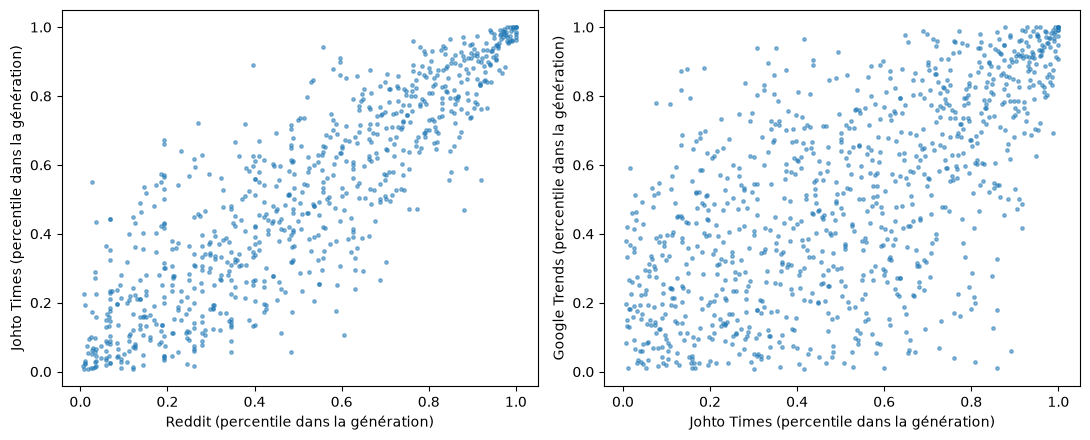

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(pop.reddit_pct_gen, pop.johto_pct_gen, s=6, alpha=.5)
axes[0].set_xlabel("Reddit (percentile dans la génération)")
axes[0].set_ylabel("Johto Times (percentile dans la génération)")
axes[1].scatter(pop.johto_pct_gen, pop.trends_pct_gen, s=6, alpha=.5)
axes[1].set_xlabel("Johto Times (percentile dans la génération)")
axes[1].set_ylabel("Google Trends (percentile dans la génération)")
plt.tight_layout()
plt.show()

In [31]:
# les plus gros désaccords entre les sondages et Google Trends
pop["ecart_trends_johto"] = pop.trends_pct_gen - pop.johto_pct_gen
cols = ["nom_fr", "generation", "johto_pct_gen", "reddit_pct_gen", "trends_pct_gen", "ecart_trends_johto"]
print("Beaucoup plus cherchés qu'aimés :")
display(pop.sort_values("ecart_trends_johto", ascending=False)[cols].head(15).round(2))
print("Beaucoup plus aimés que cherchés :")
display(pop.sort_values("ecart_trends_johto")[cols].head(10).round(2))

Beaucoup plus cherchés qu'aimés :


,nom_fr,generation,johto_pct_gen,reddit_pct_gen,trends_pct_gen,ecart_trends_johto
dex,,,,,,
349,Barpau,3,0.13,0.15,0.87,0.74
371,Draby,3,0.15,0.34,0.88,0.73
550,Bargantua,5,0.08,0.28,0.78,0.70
641,Boréas,5,0.19,0.07,0.88,0.69
374,Terhal,3,0.13,0.40,0.82,0.68
996,Frigodo,9,0.11,NaN,0.78,0.67
602,Anchwatt,5,0.15,0.35,0.79,0.64
999,Mordudor,9,0.31,NaN,0.94,0.63
645,Démétéros,5,0.35,0.07,0.94,0.59


Beaucoup plus aimés que cherchés :


,nom_fr,generation,johto_pct_gen,reddit_pct_gen,trends_pct_gen,ecart_trends_johto
dex,,,,,,
474,Porygon-Z,4,0.86,0.87,0.01,-0.85
1002,Baojian,9,0.89,NaN,0.06,-0.83
28,Sablaireau,1,0.81,0.81,0.03,-0.78
988,Rampe-Ailes,9,0.85,NaN,0.13,-0.72
233,Porygon2,2,0.76,0.64,0.04,-0.72
927,Briochien,9,0.86,NaN,0.18,-0.68
1004,Yuyu,9,0.72,NaN,0.07,-0.66
253,Massko,3,0.80,0.87,0.18,-0.62
141,Kabutops,1,0.77,0.74,0.16,-0.61


Maintenant que les noms ambigus sont retirés, les désaccords qui restent s'expliquent surtout par l'usage des jeux et par l'écriture des noms :
- **plus cherchés qu'aimés** : Barpau, Draby, Terhal, Bargantua, Anchwatt… sont surtout **utiles dans les jeux** : Barpau a une évolution très compliquée (en Milobellus), Draby et Terhal donnent Drattak et Métalosse, des Pokémon forts. Boréas, Démétéros, Sylveroy ou Mordudor sont des légendaires ou des Pokémon qu'on doit chasser d'une façon particulière. On les cherche sans doute pour savoir comment les avoir ou les faire évoluer, pas parce qu'on les aime ;
- **plus aimés que cherchés** : Porygon-Z, Baojian (*Chien-Pao*) ont des tirets ou des chiffres dans le nom, que les gens écrivent sans doute de plusieurs façons, ce qui disperse les recherches.

En gros, Google Trends mesure l'**attention** et pas l'affection. C'est pour ça qu'on garde cette source à part et qu'on ne la mélange pas avec les sondages.

## 7. Populaire partout, quelque part, ou nulle part ?

Il faut maintenant dire à partir de quand un Pokémon est « populaire » dans une source. **On prend le top 10 % de sa génération** (percentile ≥ 0,9). C'est assez strict pour ne garder que les Pokémon vraiment aimés, et on a vu plus haut que c'est justement dans le haut du classement que les sondages sont fiables (intervalle de confiance de 2 points seulement). Ensuite :
- **partout** : populaire dans toutes les sources où il apparaît ;
- **quelque part** : populaire dans au moins une source, mais pas toutes ;
- **nulle part** : populaire dans aucune.

Les générations 8 et 9 n'ont que 2 sources (pas de Reddit), les autres en ont 3.

In [32]:
SEUIL_TOP = 0.9

sources = {"reddit": "reddit_pct_gen", "johto": "johto_pct_gen", "trends": "trends_pct_gen"}
top = pd.DataFrame({s: pop[c] >= SEUIL_TOP for s, c in sources.items()})
dispo = pd.DataFrame({s: pop[c].notna() for s, c in sources.items()})
nb_top = top.sum(axis=1)
nb_dispo = dispo.sum(axis=1)
pop["nb_sources"] = nb_dispo
pop["nb_sources_top"] = nb_top
pop["categorie"] = np.select([nb_top == nb_dispo, nb_top > 0], ["partout", "quelque part"], "nulle part")
pop["categorie"].value_counts()

categorie
nulle part      852
quelque part    125
partout          48
Name: count, dtype: int64

Avec le top 10 % : **48 Pokémon sont populaires partout**, 125 quelque part, et 852 nulle part.

In [33]:
# dans quelles sources sont-ils populaires, pour ceux qui le sont « quelque part » ?
qp = top[pop.categorie == "quelque part"]
qp.apply(lambda l: " + ".join(s for s in sources if l[s]), axis=1).value_counts()

trends             41
reddit + johto     27
reddit             22
johto              20
johto + trends     13
reddit + trends     2
Name: count, dtype: int64

Parmi les « quelque part », le cas le plus fréquent est « populaire seulement sur Google Trends » (41). Ensuite viennent ceux qui sont populaires dans les deux sondages mais pas sur Google (27), puis ceux d'un seul sondage (22 pour Reddit, 20 pour le Johto Times).

In [34]:
# les populaires partout
pop.loc[pop.categorie == "partout", ["nom_fr", "generation", "reddit_pct_gen", "johto_pct_gen", "trends_pct_gen"]].sort_values(["generation", "johto_pct_gen"], ascending=[True, False]).round(2)

,nom_fr,generation,reddit_pct_gen,johto_pct_gen,trends_pct_gen
dex,,,,,
94,Ectoplasma,1,0.99,1.00,0.97
133,Évoli,1,0.97,0.99,0.99
6,Dracaufeu,1,1.00,0.99,0.99
149,Dracolosse,1,0.97,0.98,0.94
1,Bulbizarre,1,0.98,0.96,0.93
143,Ronflex,1,0.95,0.91,0.96
197,Noctali,2,1.00,1.00,1.00
248,Tyranocif,2,0.97,0.99,0.96
196,Mentali,2,0.95,0.98,0.97


Les populaires partout, ce sont les grands noms qu'on attendait : Dracaufeu, Ectoplasma, Évoli, Noctali, Lucario, Gardevoir, Amphinobi… Il y en a dans toutes les générations.

### Et avec l'incertitude ?

Pour les sondages, on refait le test avec la **borne basse** de l'intervalle de confiance au lieu du percentile : un Pokémon n'est alors « populaire » que si on est sûr à 95 % qu'il est au-dessus du seuil. On regarde combien changent de catégorie.

In [35]:
top_prudent = top.copy()
top_prudent["johto"] = pop["johto_pct_gen_bas"] >= SEUIL_TOP
# pour Reddit, l'intervalle a été calculé sur le classement global : on le ramène dans la génération
r_bas_gen = pd.Series(np.nan, index=r.index)
for g, d in r.groupby("generation"):
    bas_votes = proportion_confint(d.reddit_votes, n_reddit, method="wilson")[0] * n_reddit
    r_bas_gen[d.index] = percentile_de(d.reddit_votes, bas_votes)
top_prudent["reddit"] = r_bas_gen.reindex(pop.index) >= SEUIL_TOP
nb_top_p = top_prudent.sum(axis=1)
cat_prudente = pd.Series(np.select([nb_top_p == nb_dispo, nb_top_p > 0], ["partout", "quelque part"], "nulle part"), index=pop.index)
pd.crosstab(pop["categorie"], cat_prudente, rownames=["percentile"], colnames=["borne basse"])

borne basse,nulle part,partout,quelque part
percentile,,,
nulle part,852,0,0
partout,0,42,6
quelque part,19,0,106


Avec la borne basse de l'intervalle, la catégorie change pour **25 Pokémon** seulement : 6 « partout » deviennent « quelque part » et 19 « quelque part » deviennent « nulle part ». Les catégories sont donc assez solides.

## 8. Par pays : dans combien de pays un Pokémon est-il dans le top 10 % ?

Ici on garde le percentile par pays sur **tous** les Pokémon (pas par génération), puisque c'est cette matrice qui servira à la carte par pays.

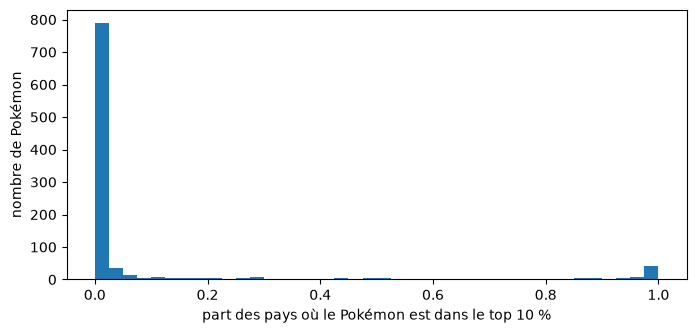

(np.int64(173), np.int64(53))

In [36]:
nb_pays_top = (pct_pays >= SEUIL_TOP).sum(axis=1)
pop["trends_nb_pays_top"] = nb_pays_top
pop["trends_part_pays_top"] = nb_pays_top / len(pays_gardes)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(pop.trends_part_pays_top, bins=40)
ax.set_xlabel("part des pays où le Pokémon est dans le top 10 %")
ax.set_ylabel("nombre de Pokémon")
plt.show()
(pop.trends_part_pays_top.between(0.01, 0.5)).sum(), (pop.trends_part_pays_top > 0.9).sum()

La plupart des Pokémon ne sont dans le top 10 % d'aucun pays ou de presque tous. 173 Pokémon sont dans le top 10 % de 1 % à 50 % des pays seulement, et 53 le sont dans plus de 90 % des pays.

In [37]:
# des Pokémon dans le top 10 % d'un petit nombre de pays seulement : où ?
peu = pop[(pop.trends_nb_pays_top > 0) & (pop.trends_nb_pays_top <= 3)].index
ex = pct_pays.loc[peu].apply(lambda l: ", ".join(l[l >= SEUIL_TOP].index), axis=1)
pd.DataFrame({"nom_fr": pop.loc[peu, "nom_fr"], "pays": ex}).head(20)

,nom_fr,pays
dex,,
11,Chrysacier,Singapore
13,Aspicot,Ireland
14,Coconfort,India
16,Roucool,"Argentina, Ecuador"
18,Roucarnage,South Africa
19,Rattata,France
22,Rapasdepic,Vietnam
23,Abo,"India, Pakistan"
24,Arbok,Malaysia


Quand un Pokémon n'est dans le top 10 % que de 1 à 3 pays, c'est souvent un Pokémon peu connu qui passe juste au-dessus du seuil grâce aux petites valeurs entières. Il faudra être prudent avant d'interpréter ces cas comme de vraies préférences nationales.

## 9. Export

In [38]:
# on garde une trace des noms ambigus (retirés de Google Trends) pour les autres notebooks
pop["trends_nom_ambigu"] = pop.index.isin(dex_ambigus)
pop.to_csv(OUT / "popularite_sources.csv")
pct_pays.to_csv(OUT / "trends_percentile_pays.csv")
mat_ratio.to_csv(OUT / "trends_ratio_gengar_pays.csv")
print(pop.shape, pct_pays.shape, mat_ratio.shape)

(1025, 18) (997, 67) (997, 171)
